# Model 4 — Multi-Region × Time Interaction Regression (2022–2025)

**Question:** How do China's monthly estimated solar-panel export-capacity trends differ across destination regions?

**Design:** Every observed destination region receives **its own intercept and monthly linear time slope**. There is **no omitted region**. Calendar-month fixed effects account for shared seasonality. The descriptive dependent variable is estimated monthly solar-panel export capacity in **GW**, based on Ember's `Capacity (MW)` field divided by 1,000.

**Data:** [Group GitHub source CSV](https://github.com/Amyzzz17/ZhengWangZhouLi/blob/main/data/Raw/mart_solar_exports_full_release_monthly.csv). The code uses only `Area type == 'Country or economy'` and `Commodity type == 'Panels'` for Jan 2022–Dec 2025 and aggregates country-level records into region-months. Already-aggregated rows are excluded.

**Model:**

\[
Y_{r,t} = lpha_r + eta_r t + \gamma_{m(t)} + 
arepsilon_{r,t}
\]

`beta_r` (GW/month) describes the absolute monthly trend for region `r`. The code tests whether all region slopes are equal and performs Holm-adjusted pairwise comparisons. The main uncertainty method is Driscoll–Kraay with 6 monthly lags, plus 3/12-lag sensitivity and residual checks.

**Reproducibility:** Run all cells, with access to the original GitHub CSV or a local copy. No pre-calculated/simulated values are used as a fallback. This notebook requires `pandas`, `numpy`, `statsmodels`, `scipy`, and `matplotlib`.

**AI-use statement:** ChatGPT assisted in drafting the initial code, documentation and report template. The team should check all outputs against the source data before submitting.

## 1. Imports and configuration
You can leave `CSV_PATH=None` to read a local repository copy or the GitHub raw URL automatically. In Colab, upload the CSV or set `CSV_PATH` to its local path if GitHub is unavailable.

In [1]:
from __future__ import annotations
import argparse
from itertools import combinations
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import t as student_t, f as fisher_f
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.sandwich_covariance import cov_nw_groupsum

RAW_URL = (
    "https://raw.githubusercontent.com/Amyzzz17/ZhengWangZhouLi/"
    "main/data/Raw/mart_solar_exports_full_release_monthly.csv"
)
SOURCE_FILENAME = "mart_solar_exports_full_release_monthly.csv"
START = "2022-01-01"
END = "2025-12-01"
MONTH_COUNT = 48
DEFAULT_LAGS = 6
SENSITIVITY_LAGS = (3, 6, 12)




# CONFIGURATION — change if needed
CSV_PATH = None
OUT_DIR = "Model4_All_Regions_Results"

## 2. Load original source and validate region-month coverage
Use only country/economy panel records. Missing or incomplete months are reported, not set to zero.

In [2]:
def read_source(csv_path: str | None = None) -> tuple[pd.DataFrame, str]:
    """Read an explicitly specified CSV, a local repository copy, or GitHub.

    A failed remote read raises an error; it does NOT silently substitute
    simulated data or older regional aggregates.
    """
    if csv_path:
        sources = [csv_path]
    else:
        cwd = Path.cwd()
        sources = []
        for base in [cwd, *list(cwd.parents)[:4]]:
            sources += [str(base / "data" / "Raw" / SOURCE_FILENAME),
                        str(base / SOURCE_FILENAME)]
        sources.append(RAW_URL)

    errors = []
    for src in dict.fromkeys(sources):
        if not src.startswith("https://") and not Path(src).is_file():
            continue
        try:
            df = pd.read_csv(src, low_memory=False)
            print(f"Loaded source: {src} ({len(df):,} rows)")
            return df, src
        except Exception as exc:
            errors.append(f"{src}: {type(exc).__name__}: {exc}")
    raise FileNotFoundError(
        "Could not load the full Ember CSV. Place it at data/Raw/" + SOURCE_FILENAME
        + " or run with --csv /path/to/file.csv. Errors: " + "; ".join(errors)
    )


def make_region_month_panel(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    required = ["Area", "Date", "Area type", "Region", "Commodity type", "Capacity (MW)"]
    missing_cols = [col for col in required if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns: {missing_cols}")

    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"], errors="coerce")
    d["Capacity (MW)"] = pd.to_numeric(d["Capacity (MW)"], errors="coerce")
    d["Region"] = d["Region"].astype("string").str.strip()
    d["Area type"] = d["Area type"].astype("string").str.strip()
    d["Commodity type"] = d["Commodity type"].astype("string").str.strip()

    filt = ((d["Area type"] == "Country or economy")
            & (d["Commodity type"] == "Panels")
            & d["Date"].between(pd.Timestamp(START), pd.Timestamp(END)))
    d = d.loc[filt].copy()
    if d.empty:
        raise ValueError("No country-level Panels observations for 2022-2025.")

    null_region = int((d["Region"].isna() | (d["Region"] == "")).sum())
    null_capacity = int(d["Capacity (MW)"].isna().sum())
    negative_capacity = int((d["Capacity (MW)"].dropna() < 0).sum())
    dup_country_month = int(d.duplicated(["Area", "Date", "Commodity type"], keep=False).sum())
    if null_region or null_capacity or negative_capacity:
        warnings.warn(f"Excluded {null_region} rows without Region, {null_capacity} "
                      f"without capacity, {negative_capacity} with negative capacity.")
    if dup_country_month:
        warnings.warn(f"Found {dup_country_month} rows sharing country/date/product; "
                      "verify product-code duplicates before interpretation.")
    d = d.loc[d["Region"].notna() & d["Region"].ne("")
              & d["Capacity (MW)"].notna() & d["Capacity (MW)"].ge(0)].copy()
    d["Region"] = d["Region"].astype(str)
    d["Date"] = d["Date"].dt.to_period("M").dt.to_timestamp()

    panel = (d.groupby(["Date", "Region"], as_index=False)["Capacity (MW)"]
             .sum(min_count=1).sort_values(["Date", "Region"]).reset_index(drop=True))
    panel["capacity_gw"] = panel["Capacity (MW)"] / 1000.0
    panel["month"] = panel["Date"].dt.month
    panel["year"] = panel["Date"].dt.year
    panel["t"] = ((panel["year"] - 2022) * 12 + panel["month"] - 1).astype(int)

    expected_dates = pd.date_range(START, END, freq="MS")
    if not set(expected_dates).issubset(set(panel["Date"])):
        absent = expected_dates.difference(pd.DatetimeIndex(panel["Date"].unique()))
        warnings.warn("Missing reporting months across ALL regions: "
                      + ", ".join(absent.strftime("%Y-%m")))
    actual_regions = sorted(panel["Region"].unique().tolist())
    if len(actual_regions) < 2:
        raise ValueError("At least two observed destination regions are required.")

    coverage = (panel.groupby("Region").agg(
        observed_months=("Date", "nunique"),
        first_month=("Date", "min"), last_month=("Date", "max"),
        total_capacity_gw=("capacity_gw", "sum")).reset_index())
    coverage["expected_months"] = MONTH_COUNT
    coverage["missing_region_months"] = MONTH_COUNT - coverage["observed_months"]
    for rec in coverage.to_dict("records"):
        if rec["missing_region_months"]:
            warnings.warn(f"{rec['Region']}: only {rec['observed_months']}/48 region-month records; "
                          "missing values are NOT set to zero.")
    checks = {
        "raw_rows": len(df), "filtered_country_panel_rows_before_missing_checks": int(filt.sum()),
        "filtered_rows_used": len(d), "n_regions": len(actual_regions),
        "regions": actual_regions, "region_month_observations": len(panel),
        "full_balanced_target": MONTH_COUNT * len(actual_regions),
        "missing_region_labels": null_region, "missing_capacity": null_capacity,
        "negative_capacity": negative_capacity,
        "duplicate_country_month_product_rows": dup_country_month,
        "date_min": str(panel.Date.min().date()), "date_max": str(panel.Date.max().date()),
    }
    print("\nAUDIT:")
    for k, v in checks.items():
        print(f"  {k}: {v}")
    print("\nREGION COVERAGE:")
    print(coverage.to_string(index=False))
    return panel, {"summary": checks, "coverage": coverage}

## 3. Fit a baseline-free model with region-specific intercepts and slopes
The design matrix includes one intercept column per Region, one Region × Time trend column per Region, and 11 shared calendar-month indicators (January is the month reference).

In [3]:
def build_design(panel: pd.DataFrame):
    """No omitted region: R intercept dummies + R trend dummies + 11 month dummies."""
    reg_names = sorted(panel.Region.unique())
    n = len(reg_names)
    D = np.column_stack([(panel.Region == r).astype(float).to_numpy() for r in reg_names])
    time = panel["t"].to_numpy(dtype=float)
    seasonal = np.column_stack([(panel.month == m).astype(float).to_numpy()
                                for m in range(2, 13)])
    design = np.column_stack([D, D * time[:, None], seasonal])
    names = ([f"intercept | {r}" for r in reg_names]
             + [f"slope | {r}" for r in reg_names]
             + [f"month | {m}" for m in range(2, 13)])
    if np.linalg.matrix_rank(design) != design.shape[1]:
        raise ValueError("Design matrix is rank-deficient. Check region/month coverage and labels.")
    return design, names, reg_names


def estimate(panel: pd.DataFrame, lags: int = DEFAULT_LAGS):
    panel = panel.sort_values(["Date", "Region"]).reset_index(drop=True)
    X, names, regions = build_design(panel)
    model = sm.OLS(panel.capacity_gw.to_numpy(), X).fit()
    time = panel.t.to_numpy(dtype=int)
    # DK/HAC uses chronological monthly scores summed across regions and
    # handles temporal autocorrelation and common contemporaneous shocks.
    cov = cov_nw_groupsum(model, nlags=lags, time=time, use_correction="hac")
    cov = (cov + cov.T) / 2
    df = int(panel.Date.nunique() - 1)
    if df < 10:
        raise ValueError("Too few observed time periods for these comparisons.")
    return model, cov, names, regions, df

## 4. Statistical inference
Driscoll–Kraay standard errors, one overall equality-of-trends test, and all pairwise slope comparisons with Holm adjustment.

In [4]:
def linear_test(estimates: np.ndarray, cov: np.ndarray, a: np.ndarray, df: int):
    estimate = float(a @ estimates)
    variance = float(a @ cov @ a)
    se = np.sqrt(max(variance, 0))
    if se == 0:
        return {"estimate": estimate, "se": 0.0, "p": np.nan,
                "ci_low": np.nan, "ci_high": np.nan}
    critical = student_t.ppf(0.975, df)
    p = 2 * student_t.sf(abs(estimate / se), df)
    return {"estimate": estimate, "se": se, "p": float(p),
            "ci_low": estimate - critical * se,
            "ci_high": estimate + critical * se}


def summarize_tests(model, cov, regions, df):
    R = len(regions)
    b = np.asarray(model.params)
    region_rows = []
    for i, name in enumerate(regions):
        a = np.zeros(len(b)); a[R + i] = 1
        res = linear_test(b, cov, a, df)
        region_rows.append({"Region": name, "slope_GW_per_month": res["estimate"],
                            "SE_DK": res["se"], "p_slope_vs_zero": res["p"],
                            "CI95_low": res["ci_low"], "CI95_high": res["ci_high"]})
    trends = pd.DataFrame(region_rows).sort_values("slope_GW_per_month", ascending=False)

    # Global hypothesis: all estimated regional slopes are identical.
    # These contrasts serve only the Wald hypothesis and do NOT select
    # any baseline in the underlying regression parameterization.
    q = R - 1
    H = np.zeros((q, len(b)))
    for i in range(q):
        H[i, R + i] = 1.0
        H[i, R + R - 1] = -1.0
    d = H @ b
    V = H @ cov @ H.T
    rank = np.linalg.matrix_rank(V)
    if rank < q:
        warnings.warn("Global Wald covariance is rank deficient; joint F/p not estimable. ")
        F, overall_p = float("nan"), float("nan")
    else:
        F = float(d.T @ np.linalg.solve(V, d) / q)
        overall_p = float(fisher_f.sf(F, q, df))
    overall = {"hypothesis": "All regional monthly trend slopes are equal",
               "F_statistic": F, "df_numerator": q,
               "df_denominator": df, "p_value": overall_p,
               "R_squared": model.rsquared, "adjusted_R_squared": model.rsquared_adj,
               "n_region_month": int(model.nobs), "n_regions": R,
               "n_unique_months": df + 1}

    pairs = []
    for (i, reg_i), (j, reg_j) in combinations(enumerate(regions), 2):
        a = np.zeros(len(b)); a[R + i] = 1; a[R + j] = -1
        res = linear_test(b, cov, a, df)
        pairs.append({"region_1": reg_i, "region_2": reg_j,
                      "difference_slope_GW_per_month": res["estimate"],
                      "SE_DK": res["se"], "p_raw": res["p"],
                      "CI95_low_unadjusted": res["ci_low"],
                      "CI95_high_unadjusted": res["ci_high"]})
    pairwise = pd.DataFrame(pairs)
    if len(pairwise):
        valid = pairwise.p_raw.notna()
        pairwise["p_holm"] = np.nan
        pairwise["significant_after_holm_5pct"] = False
        if valid.any():
            decision, corrected, _, _ = multipletests(pairwise.loc[valid,"p_raw"],
                                                     method="holm", alpha=.05)
            pairwise.loc[valid,"p_holm"] = corrected
            pairwise.loc[valid,"significant_after_holm_5pct"] = decision
        pairwise = pairwise.sort_values("p_holm")
    return trends, overall, pairwise

## 5. Diagnostics, charts, and saved tables
Check residual serial correlation and lag sensitivity before making significance claims.

In [5]:
def diagnostic_table(model, panel: pd.DataFrame):
    d = panel[["Date", "Region", "t"]].copy()
    d["residual"] = model.resid
    rows = []
    for name, g in d.sort_values("Date").groupby("Region"):
        e = g.residual.to_numpy()
        lj = acorr_ljungbox(e, lags=[6], return_df=True)
        rows.append({"Region": name, "n_months": len(g),
                     "Durbin_Watson": float(durbin_watson(e)),
                     "Ljung_Box_p_lag6": float(lj["lb_pvalue"].iloc[0]),
                     "residual_std_GW": float(np.std(e, ddof=1))})
    return pd.DataFrame(rows)


def make_charts(panel, trends, output: Path):
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                         "font.family": "DejaVu Sans", "font.size": 10})
    regions = trends.Region.tolist()
    fig, ax = plt.subplots(figsize=(11, 5.8))
    for r in regions:
        g = panel[panel.Region == r].sort_values("Date")
        ax.plot(g.Date, g.capacity_gw, label=r, linewidth=1.65, alpha=.83)
    ax.set(title="China's monthly solar-panel export capacity by destination region",
           ylabel="Estimated capacity (GW per month)", xlabel="Month")
    ax.grid(axis="y", alpha=.17)
    ax.legend(title="Region", bbox_to_anchor=(1.02,1), loc="upper left", frameon=False)
    fig.text(.10,.015,"Source: Ember China Solar Exports | Panels only | Jan 2022–Dec 2025 | Country records aggregated to regions",
             color="dimgray", fontsize=8)
    fig.tight_layout(rect=[0,.035,.84,1])
    fig.savefig(output/"region_monthly_panel_capacity.png", dpi=220, bbox_inches="tight")
    plt.close(fig)

    s = trends.sort_values("slope_GW_per_month")
    fig, ax = plt.subplots(figsize=(9.7, max(4.7, 0.7*len(s)+1.9)))
    yy = np.arange(len(s))
    x = s.slope_GW_per_month.to_numpy()
    xe = np.vstack([x-s.CI95_low.to_numpy(), s.CI95_high.to_numpy()-x])
    ax.errorbar(x, yy, xerr=xe, fmt="o", ms=6, color="#116A7B",
                ecolor="#657984", capsize=4, linewidth=1.6)
    ax.set_yticks(yy, labels=s.Region.tolist())
    ax.axvline(0, color="#666666", linestyle="--", linewidth=1)
    ax.grid(axis="x", alpha=.15)
    ax.set(xlabel="Estimated monthly capacity trend (GW/month)",
           title="Region-specific trend slopes with 95% DK confidence intervals")
    fig.text(.08,.02,"Descriptive linear trends; month fixed effects; Driscoll–Kraay SE (6 lags). Intervals are not multiplicity-adjusted.",
             color="dimgray", fontsize=8)
    fig.tight_layout(rect=[0,.05,1,1])
    fig.savefig(output/"region_slope_comparison.png", dpi=220, bbox_inches="tight")
    plt.close(fig)

## 6. Run the full regression and export outputs
When complete, results are saved to `Model4_All_Regions_Results/` and the main data tables appear below.

In [ ]:
def run(csv_path: str | None = None, outdir: str = "Model4_All_Regions_Results"):
    output = Path(outdir)
    output.mkdir(parents=True, exist_ok=True)
    raw, source = read_source(csv_path)
    panel, audit = make_region_month_panel(raw)
    model, cov, names, regions, df = estimate(panel)
    slopes, joint, pairwise = summarize_tests(model, cov, regions, df)
    diag = diagnostic_table(model, panel)
    all_parameters = []
    for i, param in enumerate(names):
        a = np.zeros(len(names)); a[i] = 1
        stat = linear_test(np.asarray(model.params), cov, a, df)
        all_parameters.append({"parameter": param, "estimate": stat["estimate"],
                               "SE_DK6": stat["se"], "p_value": stat["p"],
                               "CI95_low": stat["ci_low"],
                               "CI95_high": stat["ci_high"]})
    all_parameters = pd.DataFrame(all_parameters)
    
    coverage = audit["coverage"]
    slopes = slopes.merge(coverage[["Region","observed_months","missing_region_months",
                                    "total_capacity_gw"]], on="Region", how="left")
    annual = (panel.groupby(["year","Region"], as_index=False)["capacity_gw"]
              .sum().rename(columns={"capacity_gw":"annual_capacity_GW"}))
    specs = []
    for k in SENSITIVITY_LAGS:
        m, covk, _, _, dfx = estimate(panel, k)
        st, jt, _ = summarize_tests(m, covk, regions, dfx)
        for rec in st.to_dict("records"):
            specs.append({"DK_lags": k, "Region": rec["Region"],
                          "slope_GW_per_month": rec["slope_GW_per_month"],
                          "SE": rec["SE_DK"], "CI95_low": rec["CI95_low"],
                          "CI95_high": rec["CI95_high"],
                          "global_equal_trends_p": jt["p_value"]})
    sens = pd.DataFrame(specs)

    panel.to_csv(output/"monthly_region_panel_capacity.csv", index=False)
    annual.to_csv(output/"annual_region_capacity.csv", index=False)
    coverage.to_csv(output/"data_coverage_by_region.csv", index=False)
    slopes.to_csv(output/"regional_trend_coefficients_DK6.csv", index=False)
    all_parameters.to_csv(output/"full_regression_coefficients_DK6.csv", index=False)
    pd.DataFrame([joint]).to_csv(output/"global_equal_slopes_test.csv", index=False)
    pairwise.to_csv(output/"pairwise_slope_differences_Holm.csv", index=False)
    sens.to_csv(output/"HAC_lag_sensitivity.csv", index=False)
    diag.to_csv(output/"residual_diagnostics.csv", index=False)
    make_charts(panel, slopes, output)

    limitation = ("""Data and interpretation limitations:
- Capacity is Ember's ESTIMATED exports (MW converted to GW), not installed PV power.
- Missing country-month or region-month records are NOT imputed as zero.
- This is a descriptive linear time-trend comparison, not a causal model.
- A GW/month slope is an absolute change, NOT a percentage growth rate.
- With only 48 months, 6-lag Driscoll-Kraay inference is approximate.
- Examine lag sensitivity and residual autocorrelation before strong claims.
- Trade destination may be a first receiving market, not final installation location.
- Panels only; do not silently add Cells or Wafers to capacity totals.
- Data snapshot is updated over time; rerunning may yield revised estimates.
""")
    most = slopes.iloc[0]
    report = f"""# Model 4 — Multi-Region × Time Regression (A4 draft)

**Source:** {source}

**Research question:** How do monthly estimated solar-panel export-capacity trends from China differ by destination region, 2022–2025?

**Observations:** {len(panel)} region-month rows from {len(regions)} regions and {panel.Date.nunique()} distinct months. Source country-level Panels records are summed by region-month; no regional aggregate rows are double counted.

**Model:** `Y_rt = alpha_r + beta_r*t + month_fixed_effect_m + error_rt`, with `Y` in GW per month and `t = 0,...,47`. Each region receives its own intercept and slope. There is no omitted region. January is the omitted calendar-month indicator only.

**Inference:** Driscoll–Kraay robust covariance, 6 monthly lags; approx t and F reference distributions using T−1={df} denominator degrees of freedom; Holm family-wise correction for pairwise trend comparisons. See lag-sensitivity CSV.

## Main results

**Joint equal-slopes test:** F({joint['df_numerator']}, {joint['df_denominator']}) = {joint['F_statistic']:.3f}, p = {joint['p_value']:.4g}. This tests whether the regions share the same absolute monthly linear capacity trend.

**Largest fitted slope (NOT necessarily significantly larger):** {most.Region}, {most.slope_GW_per_month:+.4f} GW/month, 95% CI [{most.CI95_low:.4f}, {most.CI95_high:.4f}]. Compare regions using the Holm-adjusted pairwise file, not by visual ranking alone.

**Model fit:** R² = {joint['R_squared']:.3f}, adjusted R² = {joint['adjusted_R_squared']:.3f}.

**Diagnostics:** Inspect `residual_diagnostics.csv` for per-region Durbin–Watson and Ljung–Box p-values, and `HAC_lag_sensitivity.csv` for inference sensitivity at 3/6/12 lags.

## Limitations

{limitation}
"""
    (output/"Model4_A4_report_draft.md").write_text(report, encoding="utf-8")
    print("\nREGION SLOPES (GW/month; DK SE, lag 6):")
    print(slopes[["Region","slope_GW_per_month","SE_DK","CI95_low","CI95_high","p_slope_vs_zero"]].round(4).to_string(index=False))
    print("\nGLOBAL TEST:", joint)
    print("\nTOP PAIRWISE COMPARISONS (Holm adjusted):")
    print(pairwise.head(12).round(4).to_string(index=False))
    print(f"\nSaved {len(list(output.iterdir()))} output files to: {output.resolve()}")
    return {"panel": panel, "trends": slopes, "joint": joint,
            "pairwise": pairwise, "diagnostics": diag, "sensitivity": sens,
            "full_coefficients": all_parameters,
            "source": source, "output": str(output)}

Loaded source: /Users/amyz/Downloads/mart_solar_exports_full_release_monthly.csv (31,254 rows)

AUDIT:
  raw_rows: 31254
  filtered_country_panel_rows_before_missing_checks: 8810
  filtered_rows_used: 8810
  n_regions: 7
  regions: ['Africa', 'Asia', 'Europe', 'Latin America and Caribbean', 'Middle East', 'North America', 'Oceania']
  region_month_observations: 336
  full_balanced_target: 336
  missing_region_labels: 0
  missing_capacity: 0
  negative_capacity: 0
  duplicate_country_month_product_rows: 0
  date_min: 2022-01-01
  date_max: 2025-12-01

REGION COVERAGE:
                     Region  observed_months first_month last_month  total_capacity_gw  expected_months  missing_region_months
                     Africa               48  2022-01-01 2025-12-01           44.88633               48                      0
                       Asia               48  2022-01-01 2025-12-01          205.45410               48                      0
                     Europe               48 

### Region-specific slopes (GW/month)

,Region,slope_GW_per_month,SE_DK,p_slope_vs_zero,CI95_low,CI95_high,observed_months,missing_region_months,total_capacity_gw
0,Asia,0.0840,0.0210,0.0002,0.0417,0.1263,48,0,205.4541
1,Middle East,0.0494,0.0060,0.0000,0.0373,0.0615,48,0,74.9636
2,Africa,0.0361,0.0052,0.0000,0.0257,0.0465,48,0,44.8863
3,Europe,0.0156,0.0224,0.4894,-0.0295,0.0608,48,0,381.1364
4,Latin America and Caribbean,0.0129,0.0085,0.1336,-0.0041,0.0299,48,0,113.6318
5,Oceania,0.0081,0.0034,0.0208,0.0013,0.0149,48,0,26.6933
6,North America,0.0062,0.0037,0.0951,-0.0011,0.0136,48,0,3.8608


### Global test: all regions share one slope

,hypothesis,F_statistic,df_numerator,df_denominator,p_value,R_squared,adjusted_R_squared,n_region_month,n_regions,n_unique_months
0,All regional monthly trend slopes are equal,57.4316,6,47,0.0,0.8935,0.8853,336,7,48


### Pairwise comparisons (Holm adjusted)

,region_1,region_2,difference_slope_GW_per_month,SE_DK,p_raw,CI95_low_unadjusted,CI95_high_unadjusted,p_holm,significant_after_holm_5pct
4,Africa,North America,0.0299,0.0031,0.0000,0.0237,0.0360,0.0000,True
19,Middle East,Oceania,0.0413,0.0045,0.0000,0.0323,0.0503,0.0000,True
18,Middle East,North America,0.0431,0.0051,0.0000,0.0328,0.0535,0.0000,True
5,Africa,Oceania,0.0280,0.0034,0.0000,0.0212,0.0348,0.0000,True
15,Latin America and Caribbean,Middle East,-0.0365,0.0072,0.0000,-0.0509,-0.0220,0.0001,True
10,Asia,Oceania,0.0759,0.0218,0.0011,0.0320,0.1198,0.0176,True
9,Asia,North America,0.0778,0.0225,0.0012,0.0325,0.1231,0.0177,True
7,Asia,Latin America and Caribbean,0.0711,0.0219,0.0022,0.0270,0.1152,0.0303,True
2,Africa,Latin America and Caribbean,0.0232,0.0073,0.0026,0.0086,0.0378,0.0332,True
3,Africa,Middle East,-0.0133,0.0061,0.0339,-0.0255,-0.0011,0.4063,False


### Residual diagnostics

,Region,n_months,Durbin_Watson,Ljung_Box_p_lag6,residual_std_GW
0,Africa,48,0.9862,0.0124,0.3118
1,Asia,48,0.6717,0.0000,1.4292
2,Europe,48,0.6071,0.0000,1.7667
3,Latin America and Caribbean,48,0.7321,0.0000,0.5450
4,Middle East,48,0.8054,0.0000,0.4051
5,North America,48,1.1997,0.0000,0.2580
6,Oceania,48,1.0907,0.0000,0.2518


### Lag sensitivity

,DK_lags,Region,slope_GW_per_month,SE,CI95_low,CI95_high,global_equal_trends_p
0,3,Asia,0.0840,0.0203,0.0431,0.1249,0.0
1,3,Middle East,0.0494,0.0061,0.0372,0.0616,0.0
2,3,Africa,0.0361,0.0053,0.0255,0.0467,0.0
3,3,Europe,0.0156,0.0238,-0.0323,0.0636,0.0
4,3,Latin America and Caribbean,0.0129,0.0090,-0.0052,0.0310,0.0
5,3,Oceania,0.0081,0.0035,0.0011,0.0151,0.0
6,3,North America,0.0062,0.0039,-0.0017,0.0141,0.0
7,6,Asia,0.0840,0.0210,0.0417,0.1263,0.0
8,6,Middle East,0.0494,0.0060,0.0373,0.0615,0.0
9,6,Africa,0.0361,0.0052,0.0257,0.0465,0.0


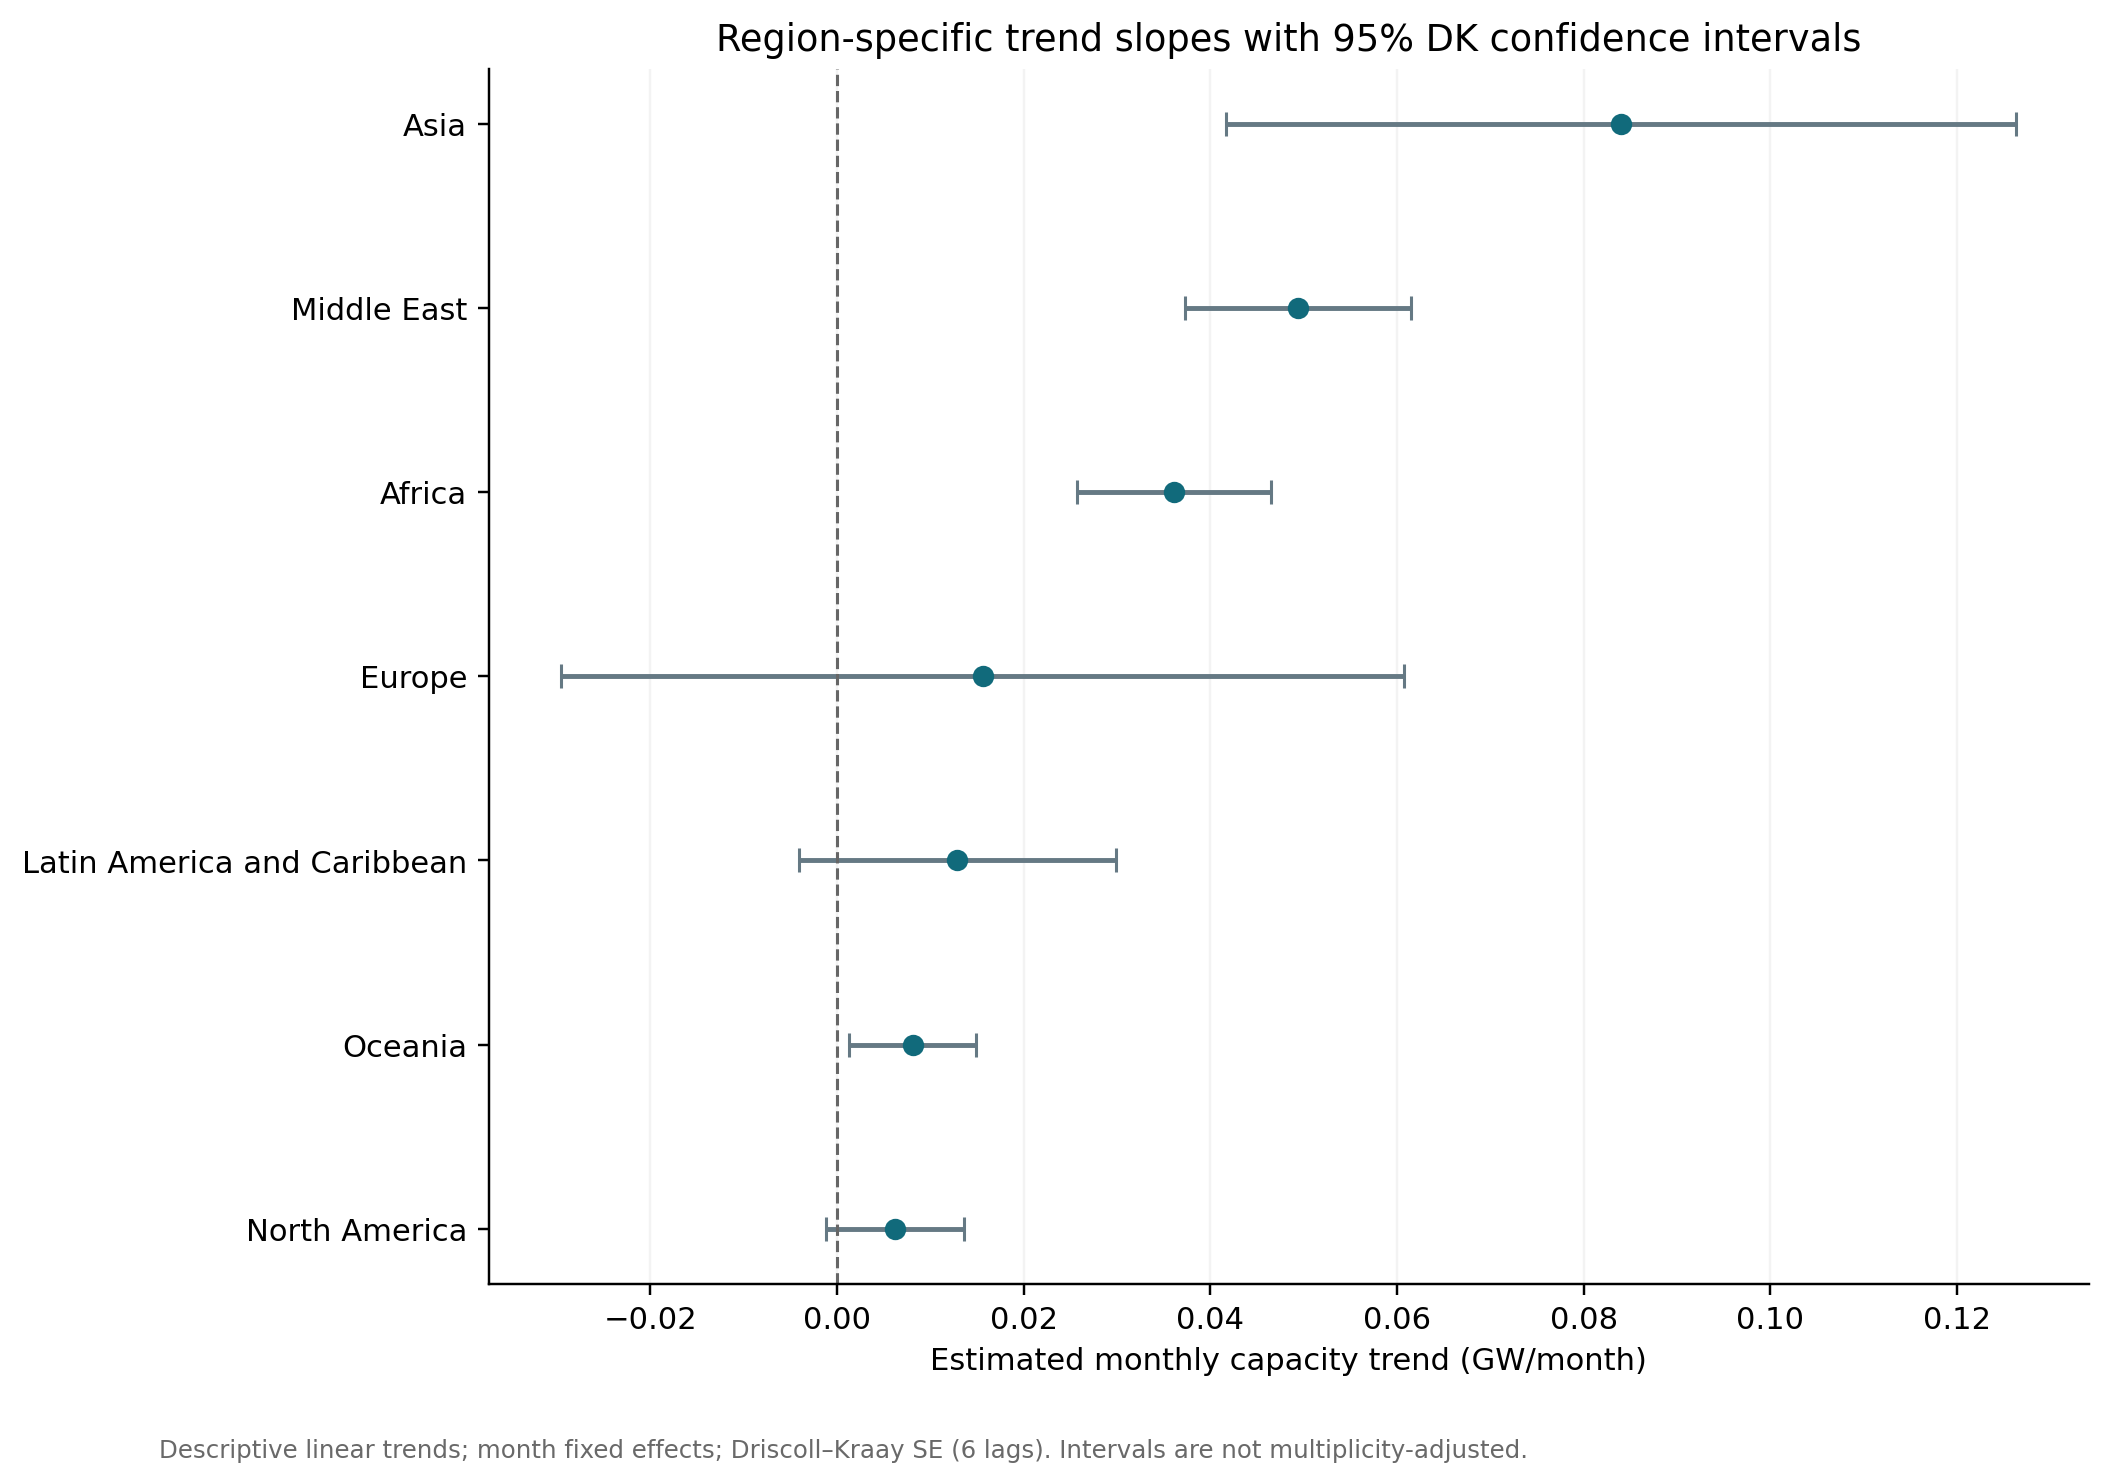

In [7]:
results = run(csv_path=CSV_PATH, outdir=OUT_DIR)
from IPython.display import display, Markdown, Image
display(Markdown("### Region-specific slopes (GW/month)"))
display(results["trends"].round(4))
display(Markdown("### Global test: all regions share one slope"))
display(pd.DataFrame([results["joint"]]).round(4))
display(Markdown("### Pairwise comparisons (Holm adjusted)"))
display(results["pairwise"].round(4))
display(Markdown("### Residual diagnostics"))
display(results["diagnostics"].round(4))
display(Markdown("### Lag sensitivity"))
display(results["sensitivity"].round(4))
display(Image(filename=str(Path(OUT_DIR) / "region_slope_comparison.png")))